## Google Colab Setup

In [ ]:
!curl https://course-v3.fast.ai/setup/colab | bash

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0curl: (6) Could not resolve host: course-v3.fast.ai


In [ ]:
!pip install torch torchvision

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from fastai import *
from fastai.vision import *
import torchvision
import torch

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Go to this URL in a browser: https://accounts.google.com/o/oauth2/auth?client_id=947318989803-6bn6qk8qdgf4n4g3pfee6491hc0brc4i.apps.googleusercontent.com&redirect_uri=urn%3aietf%3awg%3aoauth%3a2.0%3aoob&scope=email%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdocs.test%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.photos.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fpeopleapi.readonly&response_type=code

Enter your authorization code:
··········
Mounted at /content/drive


In [ ]:
from fastai import *
from fastai.vision import *

In [ ]:
ls

drive/  sample_data/


In [ ]:
cd drive/My Drive/DATA_SET

/content/drive/My Drive/DATA_SET


## ResNet34

In [ ]:
path = "/content/drive/My Drive/DATA_SET/Wavelet"
bs = 32
data = ImageDataBunch.from_folder(path, valid_pct=0.3, bs=bs)
data.normalize(imagenet_stats)

ImageDataBunch;

Train: LabelList (1725 items)
x: ImageList
Image (3, 285, 1000),Image (3, 285, 1000),Image (3, 285, 1000),Image (3, 285, 1000),Image (3, 285, 1000)
y: CategoryList
ra054_2×5,ra054_2×5,ra054_2×5,ra054_2×5,ra054_2×5
Path: /content/drive/My Drive/DATA_SET/Wavelet;

Valid: LabelList (739 items)
x: ImageList
Image (3, 285, 1000),Image (3, 285, 1000),Image (3, 285, 1000),Image (3, 285, 1000),Image (3, 285, 1000)
y: CategoryList
se204_2×14,se094_2×11,ra094_2×13,ra184_2×5,ho204_2×5
Path: /content/drive/My Drive/DATA_SET/Wavelet;

Test: None

In [ ]:
print(data.classes)
len(data.classes),data.c

['ch014_2×5', 'ch024_2×7', 'ch034_2×6', 'ch044_2×6', 'ch054_2×8', 'ch064_2×13', 'ch074_2×7', 'ch084_2×6', 'ch094_2×7', 'ch104_2×4', 'ch114_2×4', 'ch124_2×7', 'ch134_2×5', 'ch144_2×9', 'ch154_2×14', 'ch164_2×7', 'ch174_2×3', 'ch184_2×11', 'ch194_2×7', 'ch204_2×6', 'ch214_2×2', 'ch224_2×7', 'ch234_2×5', 'ch244_2×6', 'ch254_2×4', 'ch264_2×4', 'ch274_2×5', 'ch284_2×5', 'ch294_2×9', 'ch304_2×16', 'ch314_2×4', 'ch324_2×29', 'ho014_2×5', 'ho024_2×7', 'ho034_2×9', 'ho044_2×9', 'ho054_2×8', 'ho064_2×9', 'ho074_2×13', 'ho084_2×3', 'ho094_2×11', 'ho104_2×7', 'ho114_2×7', 'ho124_2×5', 'ho134_2×5', 'ho144_2×2', 'ho154_2×7', 'ho164_2×6', 'ho174_2×7', 'ho184_2×3', 'ho194_2×6', 'ho204_2×5', 'ho214_2×6', 'ho224_2×6', 'ho234_2×3', 'ho244_2×2', 'ho254_2×6', 'ho264_2×7', 'ho274_2×6', 'ho284_2×21', 'ma014_2×4', 'ma024_2×4', 'ma034_2×11', 'ma044_2×4', 'ma054_2×4', 'ma064_2×10', 'ma074_2×7', 'ma084_2×20', 'ma094_2×7', 'ma104_2×6', 'ma114_2×10', 'ma124_2×10', 'ma134_2×3', 'ma144_2×4', 'ma154_2×8', 'ma164_2×7'

(197, 197)

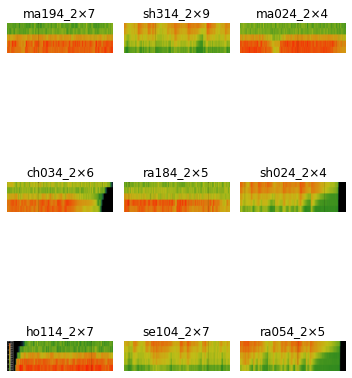

In [ ]:
data.show_batch(rows=3, figsize=(5,8))

In [ ]:
learner = create_cnn(data, torchvision.models.densenet161, metrics=[error_rate, accuracy])

/usr/local/lib/python3.6/dist-packages/fastai/vision/learner.py:109: UserWarning: `create_cnn` is deprecated and is now named `cnn_learner`.
  warn("`create_cnn` is deprecated and is now named `cnn_learner`.")


In [ ]:
def validate(NUM_EPOCHS, epoch, model, testloader):
    model.eval()
    loss = 0.0
    acc = 0
    running_loss = 0.0
    running_correct = 0
    with torch.no_grad():
        for i, data in enumerate(testloader):
            img, labels = data[0].to(device), data[1].to(device)
            new_img = new_img.to(device)
            outputs = model(new_img)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs.data, 1)
            running_loss += loss.item()
            running_correct += (preds == labels).sum().item()

    loss = running_loss / len(testset)
    acc = 100. * running_correct / len(testset)
    return loss, acc

In [ ]:
learner.fit_one_cycle(10)

epoch,train_loss,valid_loss,error_rate,accuracy,time


RuntimeError: ignored

In [ ]:
learner.save('resnet34_mtag75')

In [ ]:
interp = ClassificationInterpretation.from_learner(learner)

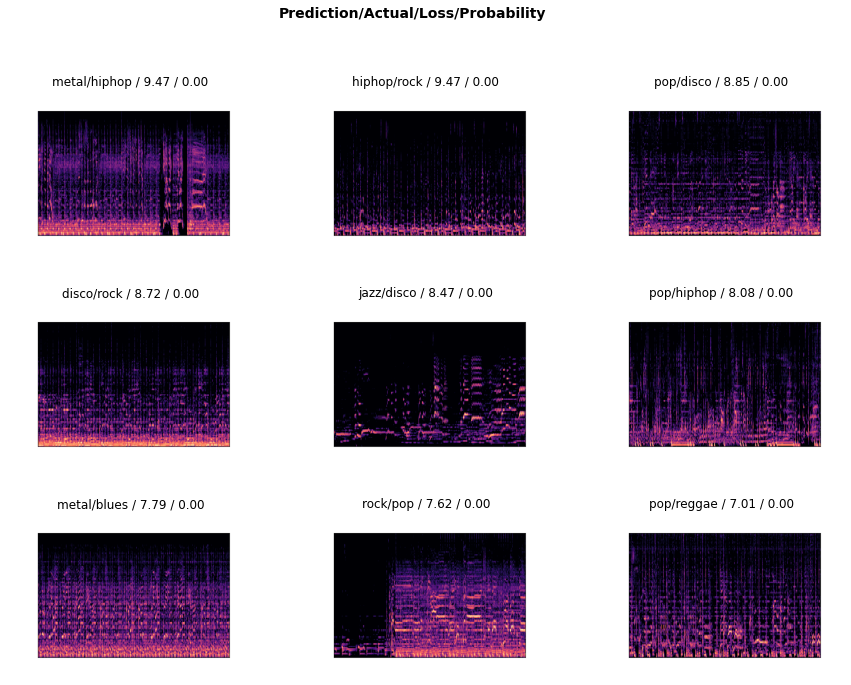

In [ ]:
interp.plot_top_losses(9, figsize=(15,11))

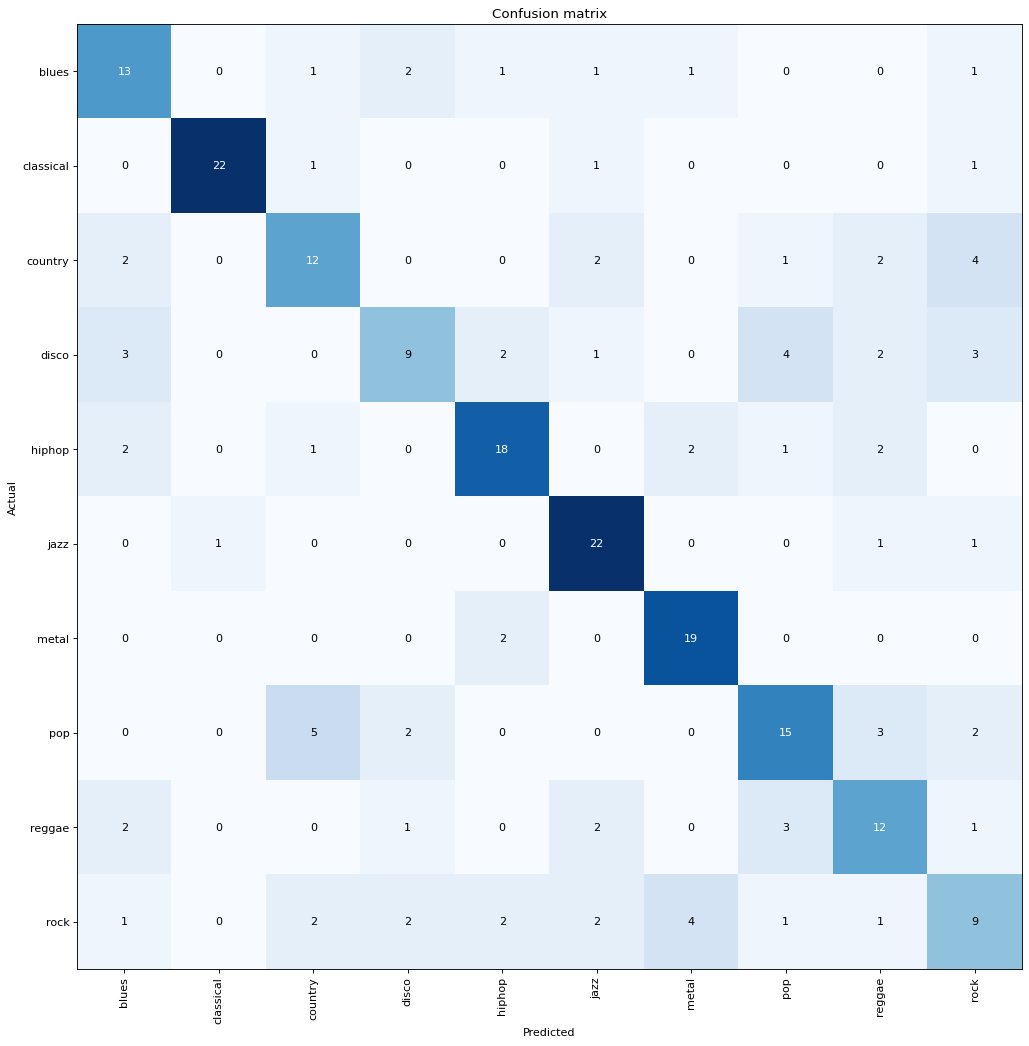

In [ ]:
interp.plot_confusion_matrix(figsize=(13,13), dpi=80)

In [ ]:
interp.most_confused(min_val=2)

[('pop', 'country', 5),
 ('country', 'rock', 4),
 ('disco', 'pop', 4),
 ('rock', 'metal', 4),
 ('disco', 'blues', 3),
 ('disco', 'rock', 3),
 ('pop', 'reggae', 3),
 ('reggae', 'pop', 3),
 ('blues', 'disco', 2),
 ('country', 'blues', 2),
 ('country', 'jazz', 2),
 ('country', 'reggae', 2),
 ('disco', 'hiphop', 2),
 ('disco', 'reggae', 2),
 ('hiphop', 'blues', 2),
 ('hiphop', 'metal', 2),
 ('hiphop', 'reggae', 2),
 ('metal', 'hiphop', 2),
 ('pop', 'disco', 2),
 ('pop', 'rock', 2),
 ('reggae', 'blues', 2),
 ('reggae', 'jazz', 2),
 ('rock', 'country', 2),
 ('rock', 'disco', 2),
 ('rock', 'hiphop', 2),
 ('rock', 'jazz', 2)]

The above code is pretty self explanatory and all credits to fastai library!

## ResNet50

In [ ]:
path = "training_set/"
bs = 8
data = ImageDataBunch.from_folder(path, valid_pct=0.3, bs=bs)
data.normalize(imagenet_stats)

ImageDataBunch;

Train: LabelList (553 items)
x: ImageList
Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432)
y: CategoryList
classical,classical,classical,classical,classical
Path: training_set;

Valid: LabelList (236 items)
x: ImageList
Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432)
y: CategoryList
disco,metal,disco,pop,classical
Path: training_set;

Test: None

In [ ]:
print(data.classes)
len(data.classes),data.c

['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


(10, 10)

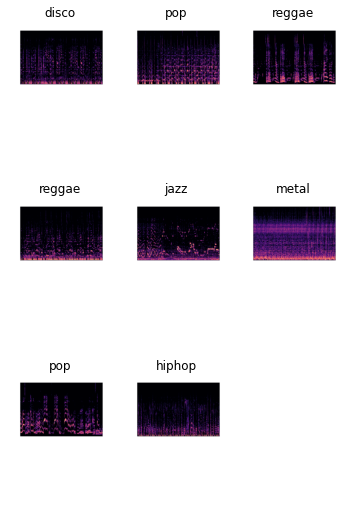

In [ ]:
data.show_batch(rows=3, figsize=(5,8))

In [ ]:
res50 = create_cnn(data, models.resnet50, metrics=accuracy)

/usr/local/lib/python3.6/dist-packages/fastai/vision/learner.py:109: UserWarning: `create_cnn` is deprecated and is now named `cnn_learner`.
  warn("`create_cnn` is deprecated and is now named `cnn_learner`.")
Downloading: "https://download.pytorch.org/models/resnet50-19c8e357.pth" to /root/.cache/torch/checkpoints/resnet50-19c8e357.pth


In [ ]:
res50.fit_one_cycle(4)

epoch,train_loss,valid_loss,accuracy,time
0,2.428385,1.788358,0.546610,00:34
1,1.735900,1.582535,0.601695,00:27
2,1.119866,1.394991,0.614407,00:27
3,0.739642,1.410773,0.584746,00:27


In [ ]:
res50.fit_one_cycle(5)

epoch,train_loss,valid_loss,accuracy,time
0,0.451199,1.444944,0.665254,00:27
1,0.675846,1.809245,0.563559,00:27
2,0.551661,1.468320,0.661017,00:27
3,0.503246,1.338569,0.656780,00:27
4,0.369078,1.321985,0.665254,00:27


In [ ]:
res50.save('ResNet50_80')

In [ ]:
interp = ClassificationInterpretation.from_learner(res50)

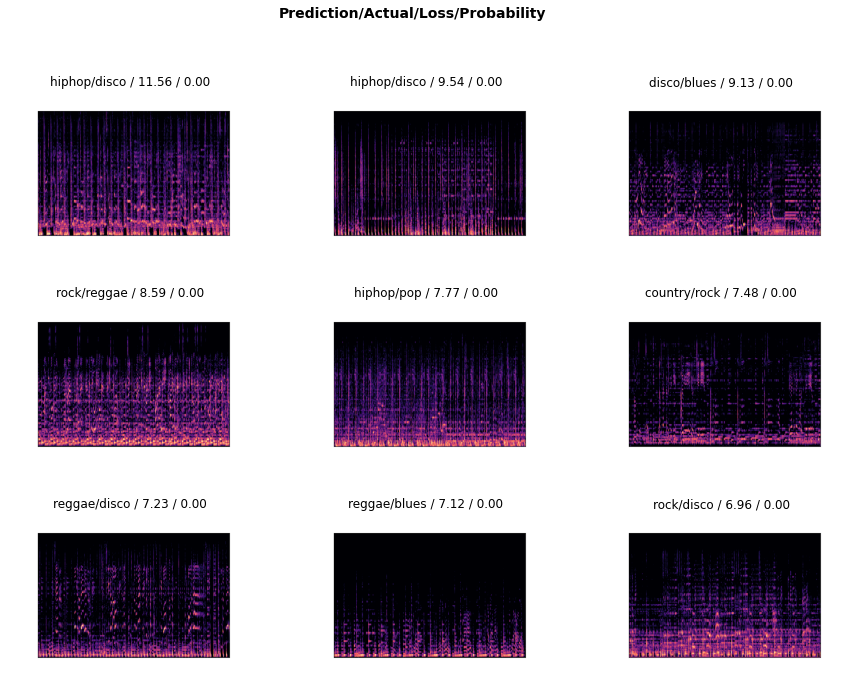

In [ ]:
interp.plot_top_losses(9, figsize=(15,11))

The plots of rock and country looks pretty similar (first two of third row).

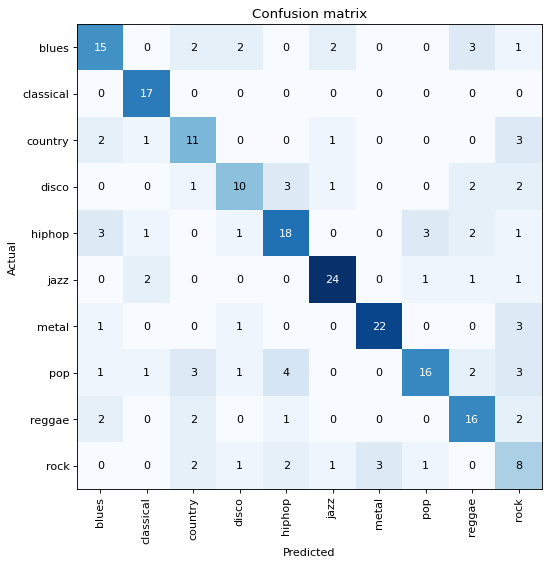

In [ ]:
interp.plot_confusion_matrix(figsize=(7, 7), dpi=80)

In [ ]:
interp.most_confused(min_val=2)

[('pop', 'hiphop', 4),
 ('blues', 'reggae', 3),
 ('country', 'rock', 3),
 ('disco', 'hiphop', 3),
 ('hiphop', 'blues', 3),
 ('hiphop', 'pop', 3),
 ('metal', 'rock', 3),
 ('pop', 'country', 3),
 ('pop', 'rock', 3),
 ('rock', 'metal', 3),
 ('blues', 'country', 2),
 ('blues', 'disco', 2),
 ('blues', 'jazz', 2),
 ('country', 'blues', 2),
 ('disco', 'reggae', 2),
 ('disco', 'rock', 2),
 ('hiphop', 'reggae', 2),
 ('jazz', 'classical', 2),
 ('pop', 'reggae', 2),
 ('reggae', 'blues', 2),
 ('reggae', 'country', 2),
 ('reggae', 'rock', 2),
 ('rock', 'country', 2),
 ('rock', 'hiphop', 2)]

## Colab memory check

In [ ]:
# # memory footprint support libraries/code
# !ln -sf /opt/bin/nvidia-smi /usr/bin/nvidia-smi
# !pip install gputil
# !pip install psutil
# !pip install humanize
import psutil
import humanize
import os
import GPUtil as GPU
GPUs = GPU.getGPUs()
# XXX: only one GPU on Colab and isn’t guaranteed
gpu = GPUs[0]
def printm():
 process = psutil.Process(os.getpid())
 print("Gen RAM Free: " + humanize.naturalsize( psutil.virtual_memory().available ), " | Proc size: " + humanize.naturalsize( process.memory_info().rss))
 print("GPU RAM Free: {0:.0f}MB | Used: {1:.0f}MB | Util {2:3.0f}% | Total {3:.0f}MB".format(gpu.memoryFree, gpu.memoryUsed, gpu.memoryUtil*100, gpu.memoryTotal))
printm()



ModuleNotFoundError: ignored